oveleaf notebook: (https://www.overleaf.com/9486175834hydqnxyrrgbq#bb9da6)

Importing libraries.

In [50]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from google.colab import drive
import xml.etree.ElementTree as ET

Defining the Station class.


In [51]:
#Station class
class stationClass:

  def __init__(self, id, name, bikeCount, minCapacity, maxCapacity, overflowCapacity, startRate, endProb, journeysStart, journeysEnd, empty, overflow, coords):
    self.Id = id
    self.Name = name
    self.BikeCount = bikeCount
    self.MinCapacity = minCapacity
    self.MaxCapacity = maxCapacity
    self.OverflowCapacity = overflowCapacity
    self.StartRate = startRate
    self.EndProb = endProb
    self.JourneysStart = journeysStart
    self.JourneysEnd = journeysEnd
    self.Empty = empty
    self.Overflow = overflow
    self.Coords = coords

  def __repr__(self):
    return (f"stationClass(id={self.Id}, name='{self.Name}', bikeCount={self.BikeCount}, minCapacity={self.MinCapacity}, maxCapacity={self.MaxCapacity}, overflowCapacity={self.OverflowCapacity}, startRate={self.StartRate}, endProb={self.EndProb}, journeysStart={self.JourneysStart}, journeysEnd={self.JourneysEnd}, empty={self.Empty}, overflow={self.Overflow}, coords={self.Coords})")

  #Getters and Setters
  @property
  def id(self):
    return self.Id

  @id.setter
  def id(self, value):
    self.Id = value

  @property
  def name(self):
    return self.Name

  @name.setter
  def name(self, value):
    self.Name = value

  @property
  def bikeCount(self):
    return self.BikeCount

  @bikeCount.setter
  def bikeCount(self, value):
    if value < 0:
      raise ValueError("Bike count can't be negative.")
    self.BikeCount = value

  @property
  def minCapacity(self):
    return self.MinCapacity

  @minCapacity.setter
  def minCapacity(self, value):
    if value < 0:
      raise ValueError("Min capacity can't be negative.")
    self.MinCapacity = value

  @property
  def maxCapacity(self):
    return self.MaxCapacity

  @maxCapacity.setter
  def maxCapacity(self, value):
    if value <= 0:
      raise ValueError("Max capacity must be greater than zero.")
    self.MaxCapacity = value

  @property
  def overflowCapacity(self):
    return self.OverflowCapacity

  @overflowCapacity.setter
  def overflowCapacity(self, value):
    if value < 0:
      raise ValueError("Overflow capacity can't be negative.")
    self.OverflowCapacity = value

  @property
  def startRate(self):
    return self.StartRate

  @startRate.setter
  def startRate(self, value):
    if value < 0:
      raise ValueError("Start rate can't be negative.")
    self.StartRate = value

  @property
  def endProb(self):
    return self.EndProb

  @endProb.setter
  def endProb(self, value):
    if not (0 <= value <= 1):
      raise ValueError("End probability must be between 0 and 1.")
    self.EndProb = value

  @property
  def journeysStart(self):
    return self.JourneysStart

  @journeysStart.setter
  def journeysStart(self, value):
    if value < 0:
      raise ValueError("Journeys start can't be negative.")
    self.JourneysStart = value

  @property
  def journeysEnd(self):
    return self.JourneysEnd

  @journeysEnd.setter
  def journeysEnd(self, value):
    if value < 0:
      raise ValueError("Journeys end can't be negative.")
    self.JourneysEnd = value

  @property
  def empty(self):
    return self.Empty

  @empty.setter
  def empty(self, value):
    if value < 0:
      raise ValueError("Empty count can't be negative.")
    self.Empty = value

  @property
  def overflow(self):
    return self.Overflow

  @overflow.setter
  def overflow(self, value):
    if value < 0:
      raise ValueError("Overflow count can't be negative.")
    self.Overflow = value

  @property
  def coords(self):
    return self.Coords

  @coords.setter
  def coords(self, value):
    self.Coords = value

  #Checks whether a station has bikes and removes one if so
  def departure(self, num):
    if self.bikeCount == 0:
      self.empty += 1
      return False
    else:
      self.bikeCount -= num
      return True

  #Adds a bike to the staion. If station has more bikes than racks, updates overflow counter
  def arrival(self, num):
    self.bikeCount += num

    if self.bikeCount > self.maxCapacity:
      self.overflow += 1


*   Reading all station data from the files and creating a station list with the data.
*   Importing information on the max capacity of each station.



In [52]:
#Getting station data
def getStationData(stationList):

  #Declaring variables
  bikeRacksMap = {}

  #Files Paths
  filePath = '/content/drive/My Drive/BelfastBikeApr21.xlsx'
  filePath2 = '/content/drive/My Drive/belfast-bike-stations-updated-25-june-2021.csv'
  filePath3 = '/content/drive/My Drive/BelfastBikesData.xml'

  #Getting data from files
  stationData = pd.read_excel(filePath)
  coordsData = pd.read_csv(filePath2)

  #Organising data by increasing station id / number
  stationData = stationData.sort_values(by='Station_id').reset_index(drop=True)
  coordsData = coordsData.sort_values(by='Station number').reset_index(drop=True)

  #Getting location of each station
  stationCoords = coordsData[['Latitude', 'Longitude']].to_numpy(dtype='float64')

  #Making a list of stations containing station data
  for i in range(len(stationData)):
    station = stationClass(id=stationData.loc[i, 'Station_id'], name=stationData.loc[i, 'Station name'], bikeCount = 0, minCapacity= 2, maxCapacity=0, overflowCapacity = 5, startRate=stationData.loc[i, 'Start rate (hr^(-1))'] / 60, endProb=stationData.loc[i, 'p_(trip end)'], journeysStart = 0, journeysEnd = 0, empty = 0, overflow  = 0,  coords=tuple(stationCoords[i]))
    stationList.append(station)

  #Parsing the XML file
  tree = ET.parse(filePath3)
  root = tree.getroot()

  #Mapping station IDs to their maxCapacity values from the XML
  for place in root.findall(".//place"):
    stationID = int(place.attrib.get("number", "0"))
    bikeRacks = int(place.attrib.get("bike_racks", "0"))
    bikeRacksMap[stationID] = bikeRacks
  bikeRacksMap[3922] = 14

  #Testing what happens when Queen’s University / Botanic Gardens and Ormeau Park get 2 more racks
  #bikeRacksMap[3934] += 2
  #bikeRacksMap[3916] += 2

  #Updating each station with its maxCapacity based on the XML data
  for station in stationList:
    if station.id in bikeRacksMap:
        station.maxCapacity = bikeRacksMap[station.id]

  return stationList

Sets an initial amount of bikes at each station.

*   It assigns bikes based on a fraction of the stations maximum capacity.
*   The fraction in caluclated, for each station, by accounting for the rate of journeys starting and ending at that station.

*   The amount of bikes is then scaled (keeping the ratios as correct as possible) to account for the number of bikes we require.
*   Some extra steps are taken to account for cases where more bikes than max capacity or less bikes than min capacity are assigned to the station.


*   Also makes sure that total number of bikes assigned is consistent with max number of bikes.

In [53]:
#Filling stations with initial bike count
def fillStations(stationList):

  #Declaring variables
  minCapacities = []
  maxCapacities = []

  #StartEnd ratio
  totalStartRate = sum(station.startRate for station in stationList)
  startEndRatio = np.array([station.startRate / (station.endProb * totalStartRate)  for station in stationList])

  #Calculate unscaled bikes (half of max capacity scaled by start-end ratio)
  unscaledBikes = [(station.maxCapacity / 2) * startEndRatio[i] for i, station in enumerate(stationList)]

  #Scaled bike distribution
  scaledBikes = (unscaledBikes / sum(unscaledBikes)) * maxNumBikes

  #Calculating initial bike line up (rounds down to ensure less than maxnumbikes)
  initialBikes = np.floor(scaledBikes)

  #Getting max and min capacity for each station
  for i, station in enumerate(stationList):
    minCapacities.append(station.minCapacity)
    maxCapacities.append(station.maxCapacity)

  #Enforces rack limit at stations (i.e. if too many bikes at a stions it just sets it to limit)
  for i in range(len(initialBikes)):
    if initialBikes[i] > maxCapacities[i] - 2:
      initialBikes[i] = maxCapacities[i] - 2
    elif initialBikes[i] < minCapacities[i]:
      initialBikes[i] = minCapacities[i]

  #Setting initial bike count
  for i, station in enumerate(stationList):
    station.bikeCount = initialBikes[i]

  #Calculating the difference caused by clipping
  difference = maxNumBikes - np.sum(initialBikes)

  #Redistributing the difference to meet the total bike count
  while difference != 0:
    if difference > 0:

      #Sorting stations by startRate / endRate in descending order (high start rate gets bikes first)
      for station in sorted(stationList, key=lambda s: s.startRate / (s.endProb * totalStartRate), reverse=True):
        if station.bikeCount < station.maxCapacity - 2:
          station.bikeCount += 1
          difference -= 1
          if difference == 0:
            break
    elif difference < 0:

      # Sorting stations by startRate / endRate in ascending order (low start rate loses bikes first)
      for station in sorted(stationList, key=lambda s: s.startRate / (s.endProb * totalStartRate)):
        if station.bikeCount > station.minCapacity:
          station.bikeCount -= 1
          difference += 1
          if difference == 0:
            break

Rebalances the system by,

*   modeling a van that, in one tick,
*   collects bikes from a station that has too many (more than the initial amount),

*   and deposits them at stations that have too few (less than the initial amount).

In [54]:
#Reassigning bikes within the system to balance it
def postmanPat(stationList, initialBikes, vanMaxCap):

  #Declaring variables
  vanBikeCount = 0

  #Calculating the difference from initial bike counts
  difference = {station.id: station.bikeCount - initialBikes[station.id] for station in stationList}

  #Converting to a list for indexing
  stationIds = list(difference.keys())
  difference = np.array(list(difference.values()))

  #Getting the index of the station with greatest overflow
  maxOverflowIndex = np.argmax(difference)
  maxOverflowId = stationIds[maxOverflowIndex]

  #Calculating number of bikes to take
  numGain = min(difference[maxOverflowIndex], vanMaxCap)

  #Updating bike count in the station
  for station in stationList:
    if station.id == maxOverflowId:
      station.departure(numGain)
      break

  #Updating van bike count and difference
  vanBikeCount += numGain
  difference[maxOverflowIndex] -= numGain

  #Distributing bikes to stations with shortages
  while vanBikeCount > 0:

    #Getting the index of the station with greatest shortage
    minOverflowIndex = np.argmin(difference)
    minOverflowId = stationIds[minOverflowIndex]

    #Determining bikes to drop off at the station
    numLose = min(abs(difference[minOverflowIndex]), vanBikeCount)

    #Updating the station with new bike count
    for station in stationList:
      if station.id == minOverflowId:
        station.arrival(numLose)
        break

    #Updating van bike count and difference
    vanBikeCount -= numLose
    difference[minOverflowIndex] += numLose

  return stationList

Probability function:  
*   checks whether a process that is based on probability should be carried out.

In [55]:
#Verification of arrival
def flip(p):
  return random.random() < p

Main simulation loop

In [56]:
#Method to run simulation of bike transfer
def runSimulation(stationList, numSteps, numStations, vanProb, vanMaxCap):

  #Declaring variables
  results = {station.id: [{'minute': 0, 'bikeCount': station.bikeCount, 'empty': 0, 'overflow': 0, 'journeysStart': 0, 'journeysEnd': 0}] for station in stationList}
  initialBikes = {station.id: station.bikeCount for station in stationList}
  stationEndProb = [station.endProb for station in stationList]

  #Run the simulation for a number of steps
  for step in range(1, numSteps + 1):
    for station in stationList:
      if flip(station.startRate):
        if station.departure(1):

          #Updating journeys started at station
          station.journeysStart += 1

          #Removing start station from choices
          filteredStations, filteredProbs = zip(*[(s, p) for s, p in zip(stationList, stationEndProb) if s != station])
          filteredProbs = np.array(filteredProbs) / sum(filteredProbs)

          #Choosing a random end station based on end probabilities
          endStation = np.random.choice(filteredStations, p=filteredProbs)

          #Updating bike to arrived
          endStation.arrival(1)

          #Updating journeys ended at end station
          endStation.journeysEnd += 1

    #Checks if a day has passed
    if step % (60 * 24) == 0:
      for station in stationList:

        #Record the state of each station after this step
        results[station.id].append({'minute': step, 'bikeCount': station.bikeCount, 'empty': station.empty, 'overflow': station.overflow, 'journeysStart': station.journeysStart, 'journeysEnd': station.journeysEnd})
        station.empty = 0
        station.overflow = 0
        station.journeysStart = 0
        station.journeysEnd = 0

    if flip(vanProb):
      postmanPat(stationList, initialBikes, vanMaxCap)

  return results

Printing results in a table to view them

In [57]:
#Printing results
def printResults(stationList, results, numStations):

  #Declaring variables
  totalInitial = 0
  totalCapacity = 0
  totalFinal = 0
  totalEmpty = 0
  totalOverflow = 0
  totalStart = 0
  totalEnd = 0

  #Printing header
  print(f"\n| {'Station Name':<50} | {'Max Capacity':<15} | {'Initial Bikes':<15} | {'Final Bikes':<15} | {'Min Bikes':<10} | {'Max Bikes':<10} | {'Empty Events':<15} | {'Overflow Events':<15} | {'Start Number':<15} | {'End Number':<10} |")

  #Printing horizontal line
  print('-' * 201)

  #Colours
  colours = {
      'reset': '\033[0m',
      'yellow': '\033[93m',
      'green': '\033[32m',
      'red': '\033[91m',
      'pink': '\033[95m',
      'blue': '\033[94m',
  }

  #Printing each row
  for i, station in enumerate(stationList):

    #Delcairng variables
    startNum = np.zeros(numStations)
    endNum = np.zeros(numStations)
    bikeCount = []
    empty = np.zeros(numStations)
    overflow = np.zeros(numStations)

    #Getting history of bike data
    history = results[station.id]
    maxCapacity = station.maxCapacity
    initialBike = history[0]['bikeCount']
    finalBike = history[-1]['bikeCount']

    for record in history:
      bikeCount.append(record['bikeCount'])
      empty[i] += record['empty']
      overflow[i] += record['overflow']
      startNum[i] += record['journeysStart']
      endNum[i] += record['journeysEnd']

    maxBikes = max(bikeCount)
    minBikes = min(bikeCount)

    #Calculating totals
    totalCapacity += station.maxCapacity
    totalStart += startNum[i]
    totalEnd += endNum[i]
    totalInitial += initialBike
    totalFinal += finalBike
    totalEmpty += empty[i]
    totalOverflow += overflow[i]

    #Resetting entry colour
    reset = colours['reset']
    initialBikesColour = reset
    finalBikesColour = reset
    minBikesColour = reset
    maxBikesColour = reset
    overFlowColour = reset
    emptyColour = reset

    #Gets entry colour
    if initialBike == 0:
      initialBikesColour = colours['blue']
    elif initialBike < station.minCapacity:
      initialBikesColour = colours['pink']
    elif initialBike > station.maxCapacity + station.overflowCapacity:
      initialBikesColour = colours['red']
    elif initialBike > station.maxCapacity:
      initialBikesColour = colours['yellow']
    else:
      initialBikesColour = colours['green']

    #Gets entry colour
    if finalBike == 0:
      finalBikesColour = colours['blue']
    elif finalBike < 5:
      finalBikesColour = colours['pink']
    elif finalBike > station.maxCapacity + station.overflowCapacity:
      finalBikesColour = colours['red']
    elif finalBike > station.maxCapacity:
      finalBikesColour = colours['yellow']
    else:
      finalBikesColour = colours['green']

    #Gets entry colour
    if minBikes == 0:
      minBikesColour = colours['blue']
    elif minBikes < station.minCapacity:
      minBikesColour = colours['pink']
    elif minBikes > station.maxCapacity + station.overflowCapacity:
      minBikesColour = colours['red']
    elif minBikes > station.maxCapacity:
      minBikesColour = colours['yellow']
    else:
      minBikesColour = colours['green']

    #Gets entry colour
    if maxBikes == 0:
      maxBikesColour = colours['blue']
    elif maxBikes < station.minCapacity:
      maxBikesColour = colours['pink']
    elif maxBikes > station.maxCapacity + station.overflowCapacity:
      maxBikesColour = colours['red']
    elif maxBikes > station.maxCapacity:
      maxBikesColour = colours['yellow']
    else:
      maxBikesColour = colours['green']

    #Gets entry colour
    if overflow[i] > 250:
      overflowColour = colours['red']
    elif overflow[i] > 50:
      overflowColour = colours['yellow']
    else:
      overflowColour = colours['green']

    #Gets entry colour
    if empty[i] > 250:
      emptyColour = colours['red']
    elif empty[i] > 50:
      emptyColour = colours['yellow']
    else:
      emptyColour = colours['green']

    #Printing the row with individual coloured entries
    print(
        f"| {station.name:<50} "
        f"| {maxCapacity:<15} "
        f"| {initialBikesColour}{initialBike:<15}{reset} "
        f"| {finalBikesColour}{finalBike:<15}{reset} "
        f"| {minBikesColour}{minBikes:<10}{reset} "
        f"| {maxBikesColour}{maxBikes:<10}{reset} "
        f"| {emptyColour}{empty[i]:<15}{reset} "
        f"| {overflowColour}{overflow[i]:<15}{reset} "
        f"| {startNum[i]:<15} "
        f"| {endNum[i]:<10} |"
    )

  #Printing horizontal line
  print('-' * 201)

  #Printing totals
  print(f"| {'Total':<50} | {totalCapacity:<15} | {totalInitial:<15} | {totalFinal:<15} | {' ':<10} | {' ':<10} | {totalEmpty:<15} | {totalOverflow:<15} | {totalStart:<15} | {totalEnd:<10} |\n")

Plotting Graphs for changing number of vans

In [58]:
#Plotting graphs
def plotGraphsChangingNumVans(stationList, results):

  #Declaring variables
  totalEmpty = np.zeros(len(results))
  totalOverflow = np.zeros(len(results))

  for simNum, simResult in enumerate(results):
    for station in stationList:
      history = simResult[station.id]

      for record in history:
        totalEmpty[simNum] += record['empty']
        totalOverflow[simNum] += record['overflow']

  negativeOutcomes = totalEmpty + totalOverflow
  numberOfDrivers = range(len(results))

  #Plotting negative outcomes vs number of van drivers
  plt.figure(figsize=(10, 6))
  plt.plot(numberOfDrivers, negativeOutcomes, linestyle='-', marker='o')
  plt.xlabel("\nNumber of Drivers", fontsize=12, fontweight='bold')
  plt.ylabel("Undesirable Events", fontsize=12, fontweight='bold')
  plt.grid(linestyle='--', alpha=0.7)
  plt.savefig('NumOfVansGraph.pdf')

  #Calculating first and second derivatives
  firstDerivative = np.gradient(negativeOutcomes)
  secondDerivative = np.gradient(firstDerivative)

  #Plotting first derivative
  plt.figure(figsize=(10, 6))
  plt.plot(numberOfDrivers, firstDerivative, linestyle='-', marker='o')
  plt.xlabel("\nNumber of Drivers", fontsize=12, fontweight='bold')
  plt.ylabel("First Derivative of Undesirable Events", fontsize=12, fontweight='bold')
  plt.axhline(y=0, color='black', linestyle='--', alpha=0.7)
  plt.grid(linestyle='--', alpha=0.7)
  plt.savefig('FirstDerivativeGraph.pdf')

  #Plotting second derivative
  plt.figure(figsize=(10, 6))
  plt.plot(numberOfDrivers, secondDerivative, linestyle='-', marker='o')
  plt.xlabel("Number of Drivers", fontsize=10, fontweight='bold')
  plt.ylabel("Second Derivative of Undesirable Events", fontsize=10, fontweight='bold')
  plt.axhline(y=0, color='black', linestyle='--', alpha=0.7)
  plt.grid(linestyle='--', alpha=0.7)
  plt.savefig('SecondDerivativeGraph.pdf')

  #Finding the optimal number of vans from the second derivate graph
  optimalVanCountIndex = np.argmin(np.abs(secondDerivative))
  optimalVanCount = numberOfDrivers[optimalVanCountIndex]
  return optimalVanCount

Plotting graphs

In [59]:
#Plotting graphs
def plotGraphs(stationList, results, num):

  #Delcaring variables
  totalEmptysPerStation = {station.id: 0 for station in stationList}
  totalOverflowsPerStation = {station.id: 0 for station in stationList}
  totalJourneysStart = {station.id: 0 for station in stationList}
  totalJourneysEnd = {station.id: 0 for station in stationList}

  stationNames = [station.name for station in stationList]
  totalRentalsPerDay = np.zeros(30)
  days = np.arange(1, len(totalRentalsPerDay) + 1)

  for station in stationList:
    history = results[station.id]

    #Getting totals per station
    for record in history:
      totalEmptysPerStation[station.id] += record['empty']
      totalOverflowsPerStation[station.id] += record['overflow']
      totalJourneysStart[station.id] += record['journeysStart']
      totalJourneysEnd[station.id] += record['journeysEnd']

    #Getting daily rentals
    for day in days:
      totalRentalsPerDay[day - 1] += history[day]['journeysStart']

  #Getting a list of rentals and returns
  empty = [totalEmptysPerStation[station.id] for station in stationList]
  overflow = [totalOverflowsPerStation[station.id] for station in stationList]
  rentals = [totalJourneysStart[station.id] for station in stationList]
  returns = [totalJourneysEnd[station.id] for station in stationList]

  #Setting bar width
  barWidth = 0.6

  #Creating y-axis positions
  yPos = np.arange(len(stationNames)) * 2

  #Plotting stacked horizontal bar chart
  plt.figure(figsize=(14, 20))

  #Journeys Started with Empty Events stacked first
  plt.barh(yPos, empty, barWidth, color='red', label="Empty Events")
  plt.barh(yPos, rentals, barWidth, color='blue', label="Journeys Started", left=empty)

  #Journeys Ended with Overflow Events stacked first
  plt.barh(yPos + barWidth, overflow, barWidth, color='pink', label="Overflow Events")
  plt.barh(yPos + barWidth, returns, barWidth, color='green', label="Journeys Ended", left=overflow)

  plt.xlabel("Total Events", fontsize=12, fontweight='bold')
  plt.ylabel("Station Name", fontsize=12, fontweight='bold')
  plt.yticks(yPos + barWidth / 2, stationNames)
  plt.legend()
  plt.grid(axis='x', linestyle='--', alpha=0.7)
  plt.savefig(f'Results{num}.pdf', bbox_inches='tight')

  #Plotting total number of bikes rented per day
  plt.figure(figsize=(10, 6))
  plt.bar(days, totalRentalsPerDay, color='blue')
  plt.xlabel("Day Number", fontsize=10, fontweight='bold')
  plt.ylabel("Total Bikes Rented", fontsize=10, fontweight='bold')
  plt.grid(linestyle='--', alpha=0.7)
  plt.xticks(days)
  plt.savefig(f'DailyRentals{num}.pdf', bbox_inches='tight')

Plotting negative outcome comparison between optimal number of vans and no vans

In [60]:
def plotComparison(stationList, results, optimalVanCount,):

  #Declaring variables
  totalEmptysPerStation = {station.id: 0 for station in stationList}
  totalOverflowsPerStation = {station.id: 0 for station in stationList}

  stationNames = [station.name for station in stationList]

  negativeOutcomesWithVans = np.zeros(len(stationList))
  negativeOutcomesNoVans = np.zeros(len(stationList))

  for i, station in enumerate(stationList):
    historyOptimal = results[optimalVanCount][station.id]
    historyNone = results[0][station.id]

    #Calculating totals
    totalEmptyWithVans = 0
    totalOverflowWithVans = 0
    totalEmptyNoVans = 0
    totalOverflowNoVans = 0

    for record in historyOptimal:
      totalEmptyWithVans += record['empty']
      totalOverflowWithVans += record['overflow']

    for record in historyNone:
      totalEmptyNoVans += record['empty']
      totalOverflowNoVans += record['overflow']

    #Calculating negative outcomes (empty + overflow) for each scenario
    negativeOutcomesWithVans[i] = totalEmptyWithVans + totalOverflowWithVans
    negativeOutcomesNoVans[i] = totalEmptyNoVans + totalOverflowNoVans

  #Plotting horizontal bar graph comparing the two scenarios (with and without vans)
  plt.figure(figsize=(14, 20))

  #Setting bar width
  barWidth = 0.6

  #Creating y-axis positions
  yPos = np.arange(len(stationNames)) * 2

  # Plot bars for both scenarios
  plt.barh(yPos, negativeOutcomesWithVans, barWidth, color='blue', label="Optimal Van Count")
  plt.barh(yPos + barWidth, negativeOutcomesNoVans, barWidth, color='red', label="No Vans")

  plt.xlabel("\nTotal Number of Undesirable Events (Empty + Overflow)", fontsize=20, fontweight='bold')
  plt.ylabel("Station Name", fontsize=20, fontweight='bold')
  plt.yticks(yPos, stationNames)
  plt.legend()
  plt.grid(axis='x', linestyle='--', alpha=0.7)
  plt.savefig('Negative.pdf', bbox_inches='tight')

Main code block which calls functions

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

| Station Name                                       | Max Capacity    | Initial Bikes   | Final Bikes     | Min Bikes  | Max Bikes  | Empty Events    | Overflow Events | Start Number    | End Number |
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
| City Hall                                          | 20              | 10.0            | 15.0            | 0.0        | 50.0       | 73.0            | 231.0           | 1309.0          | 1314.0     |
| Victoria Square                                    | 10              | 5.0             | 0.0             | 0.0        | 23.0       | 21.0            | 78.0            | 225.0           | 220.0      |
| Donegall Quay                                      | 16     

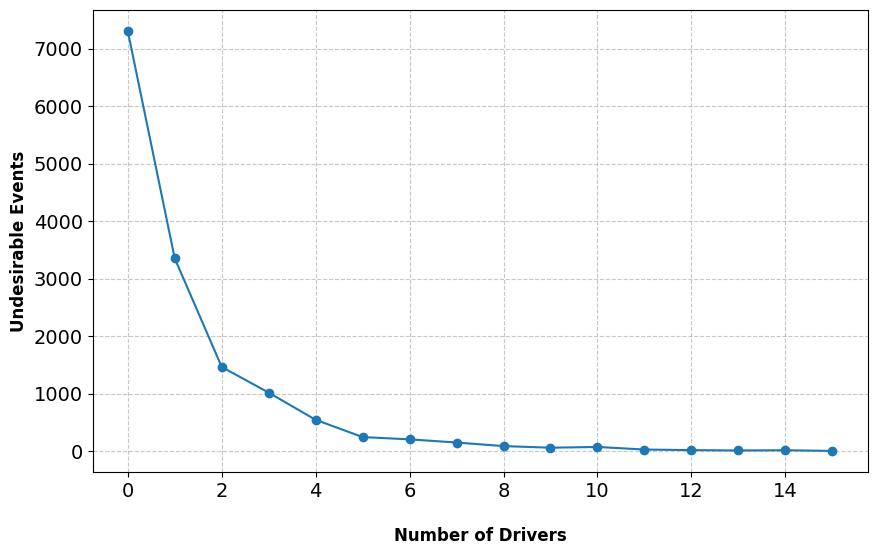

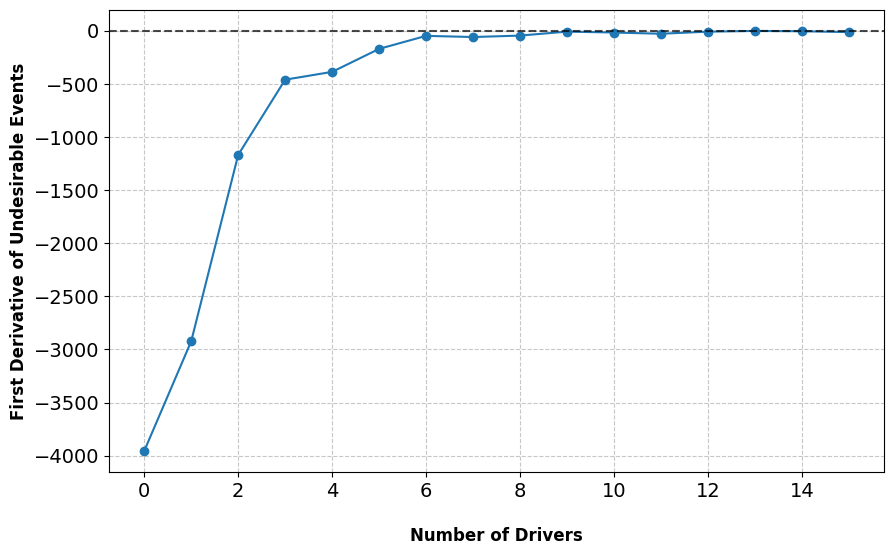

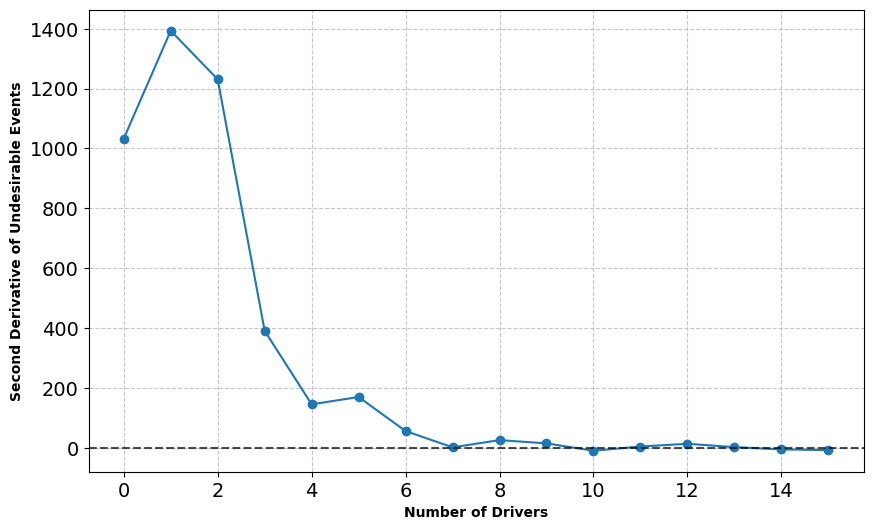

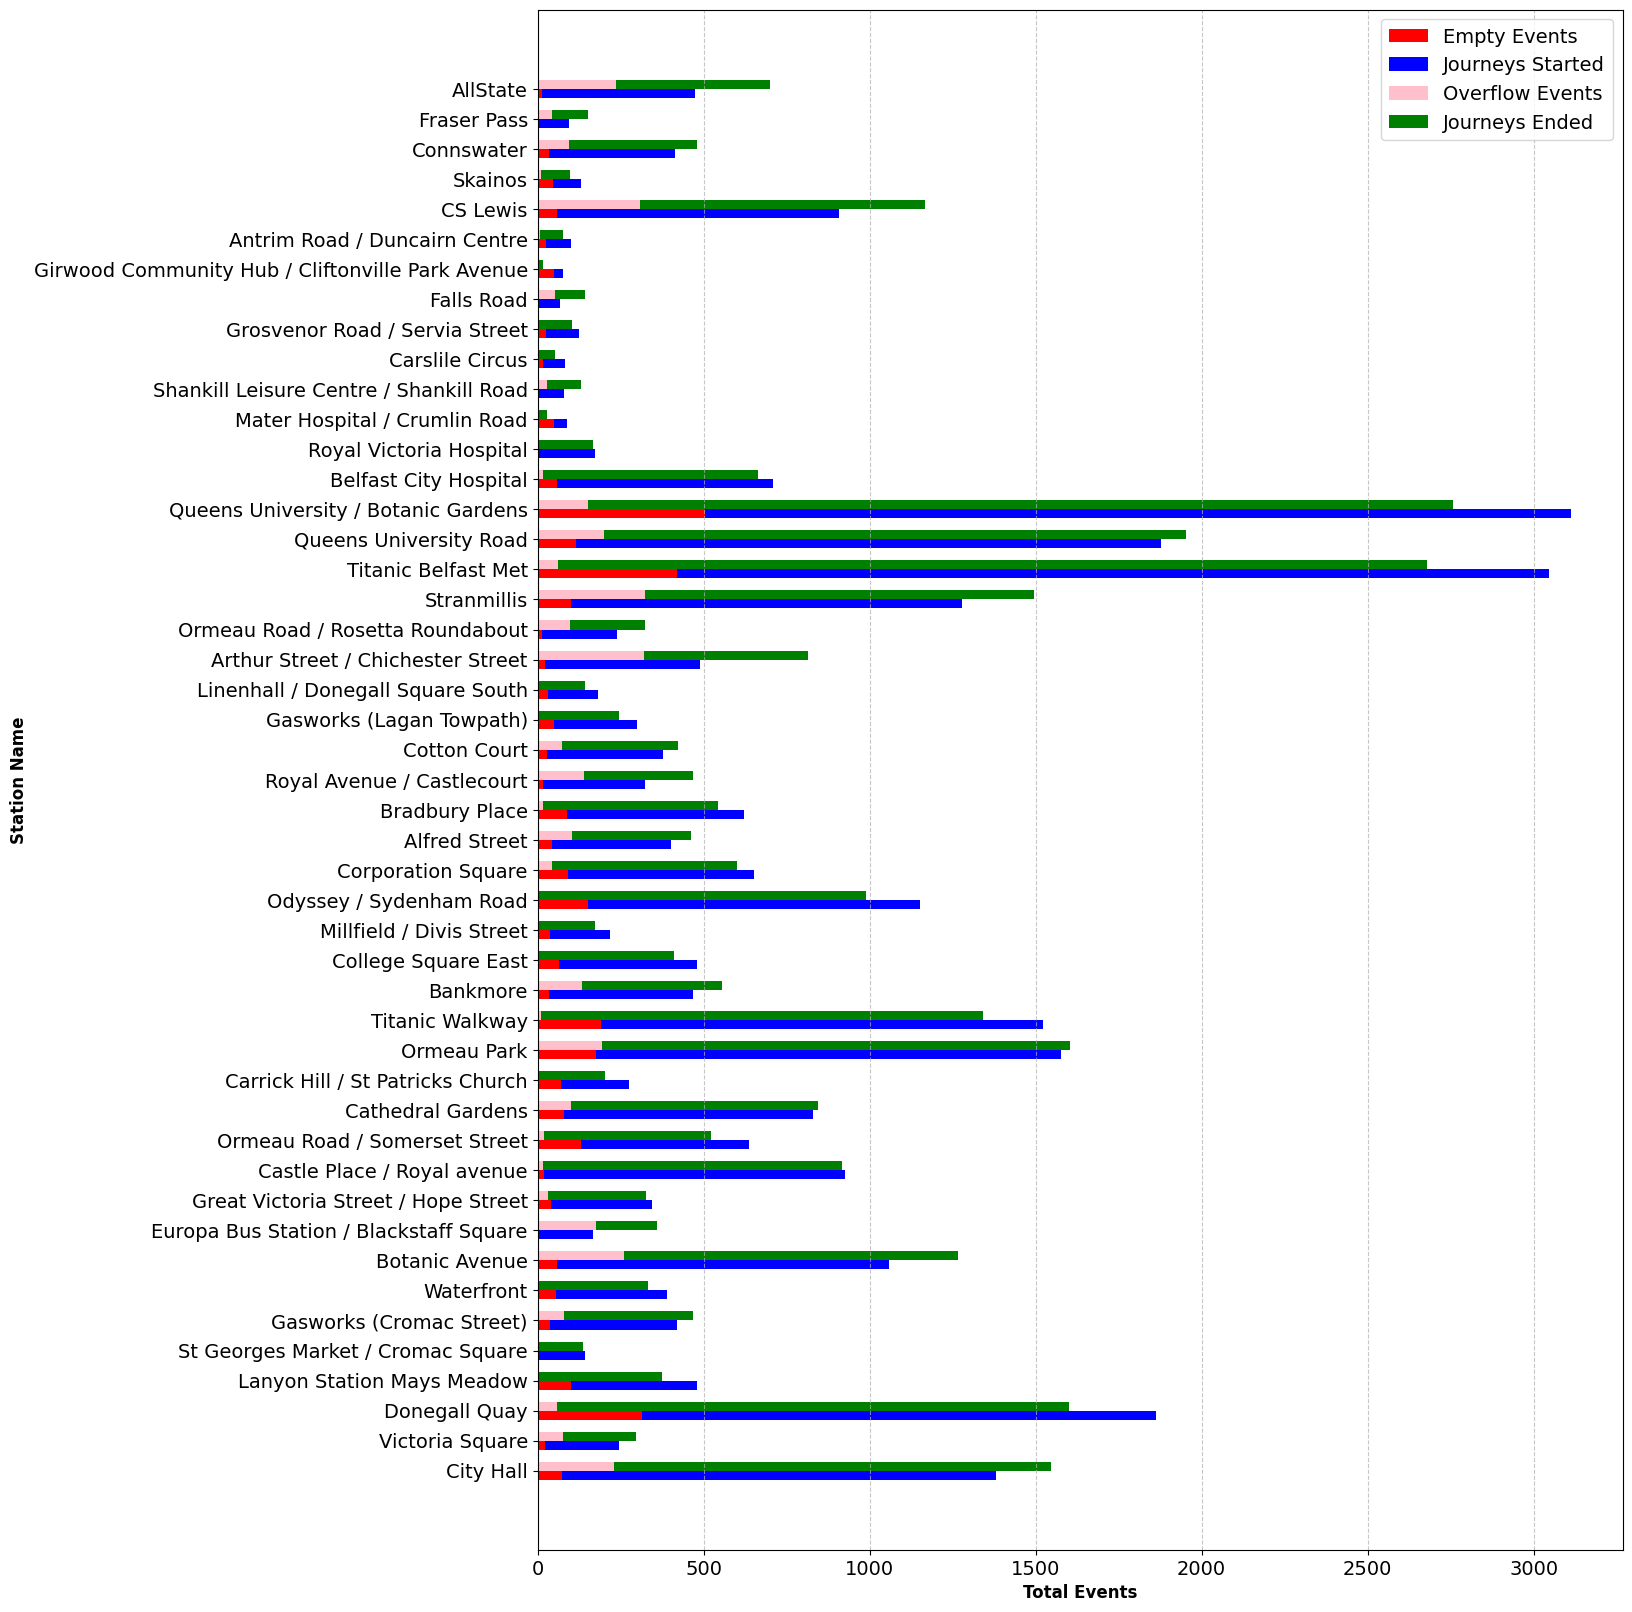

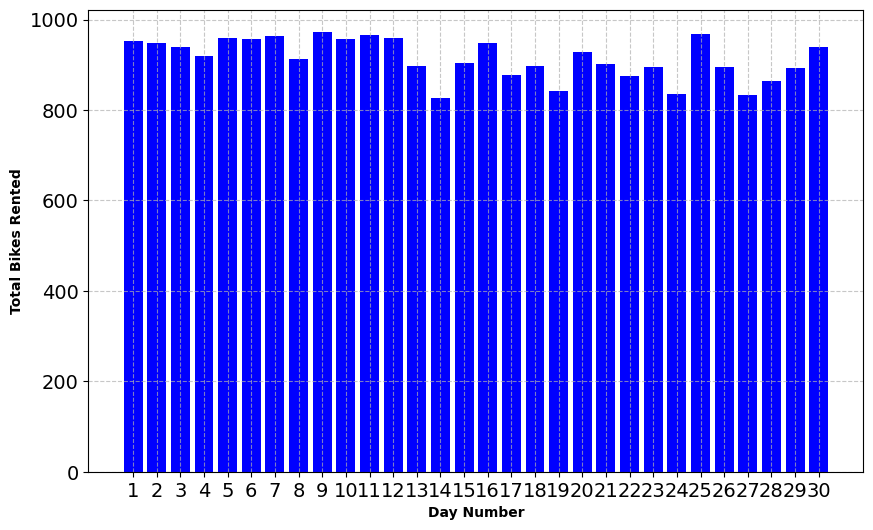

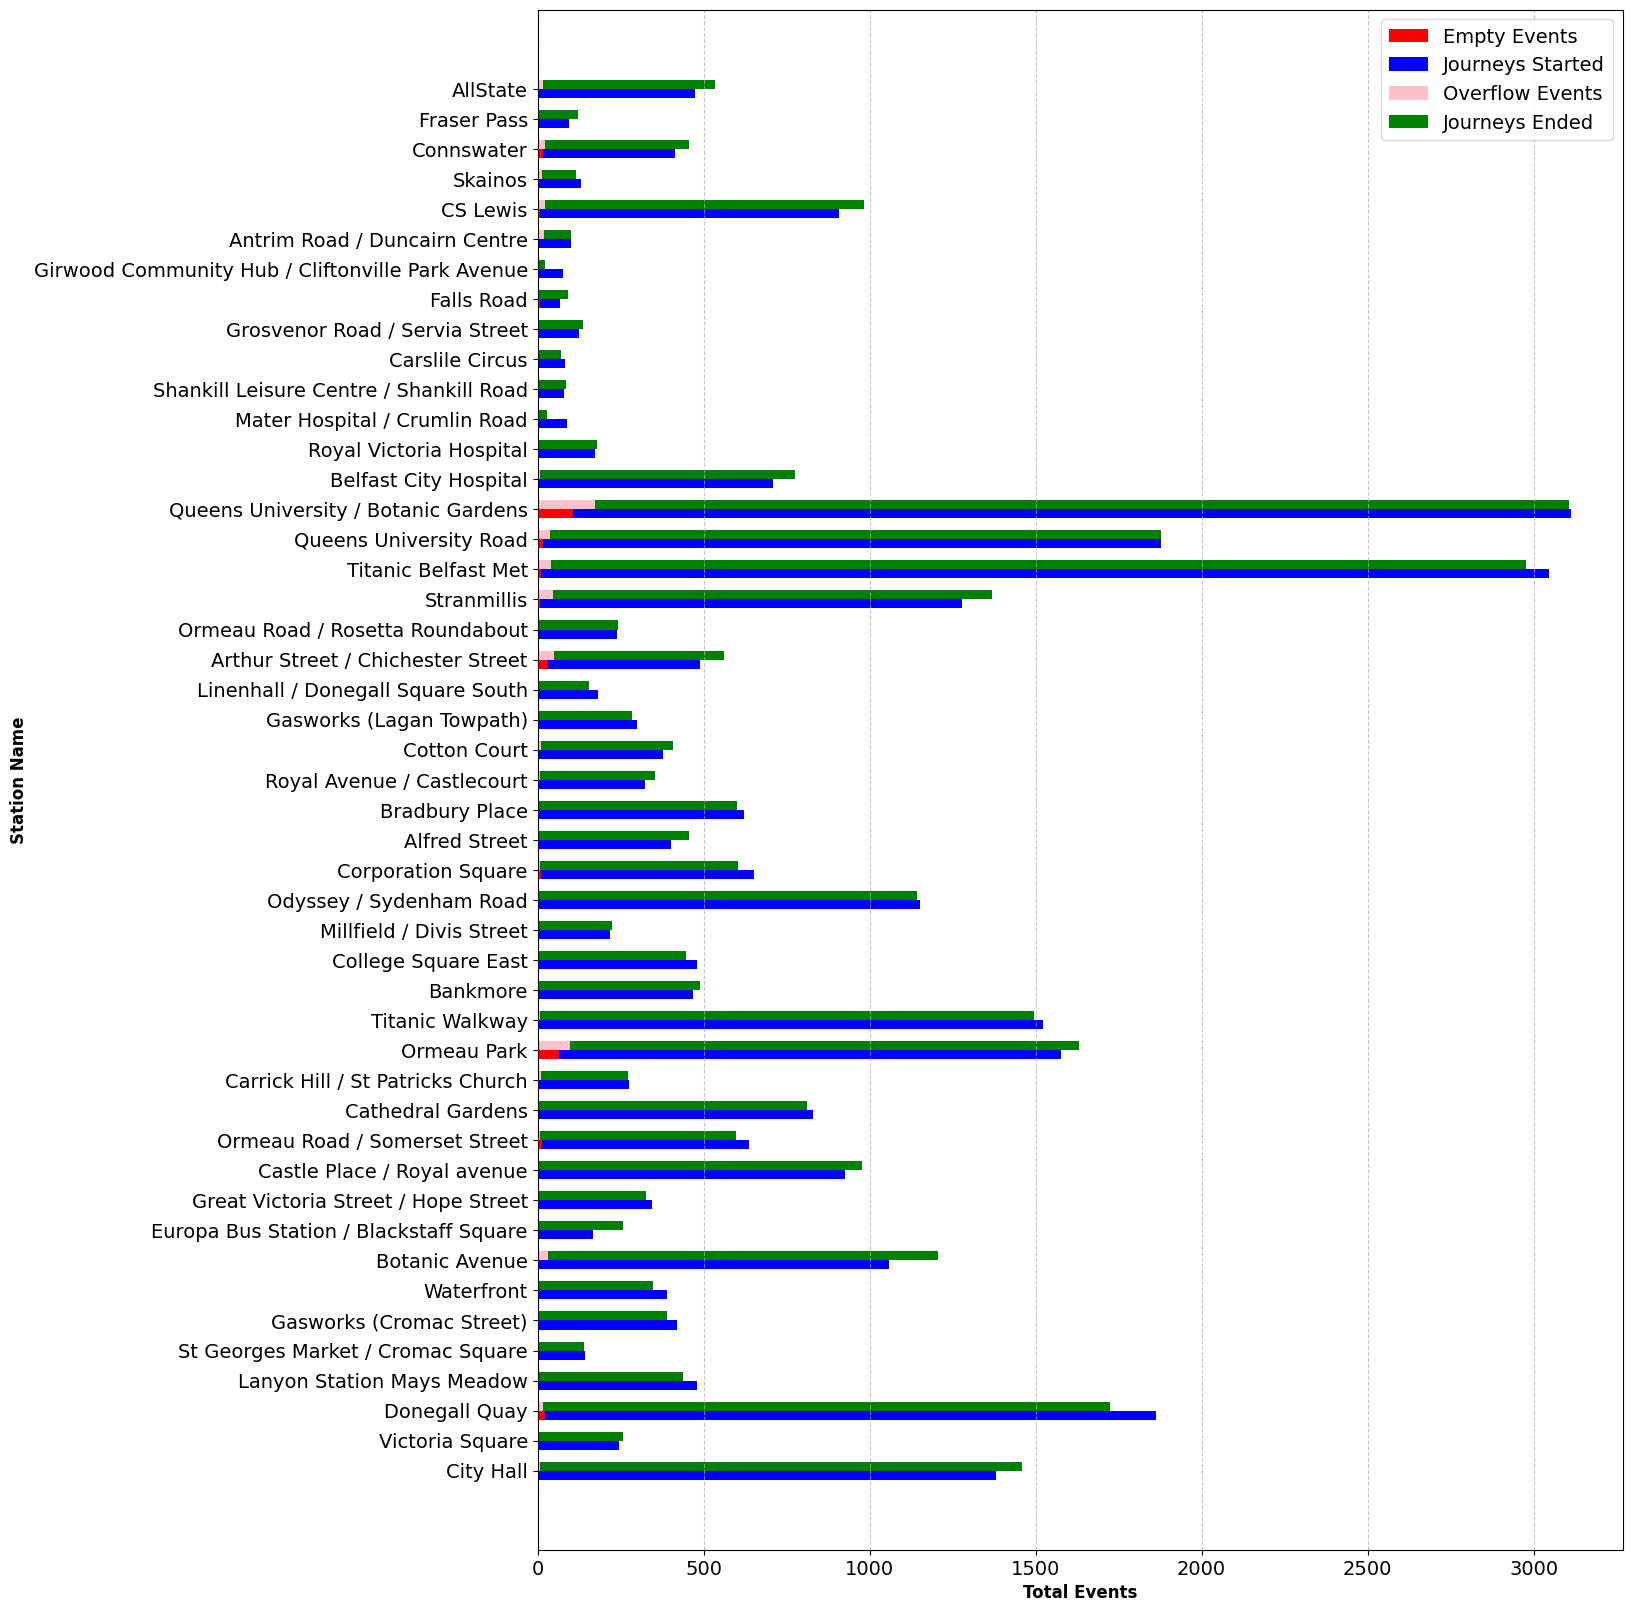

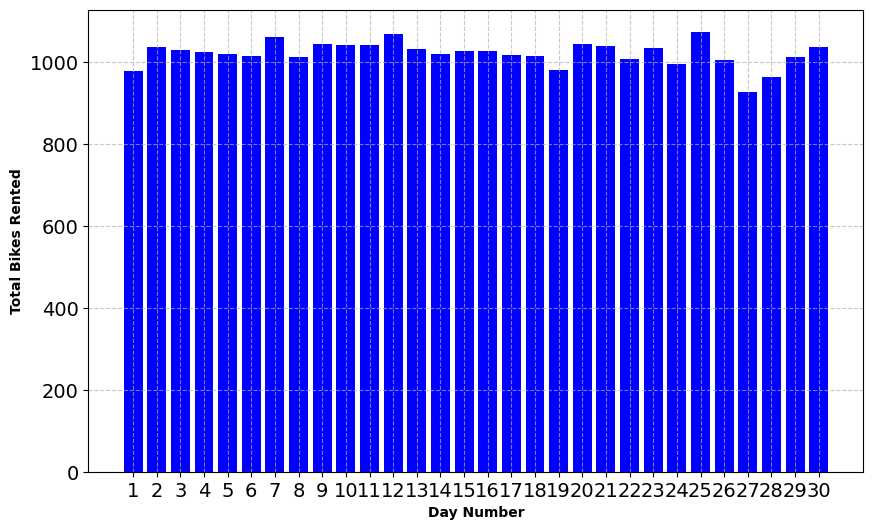

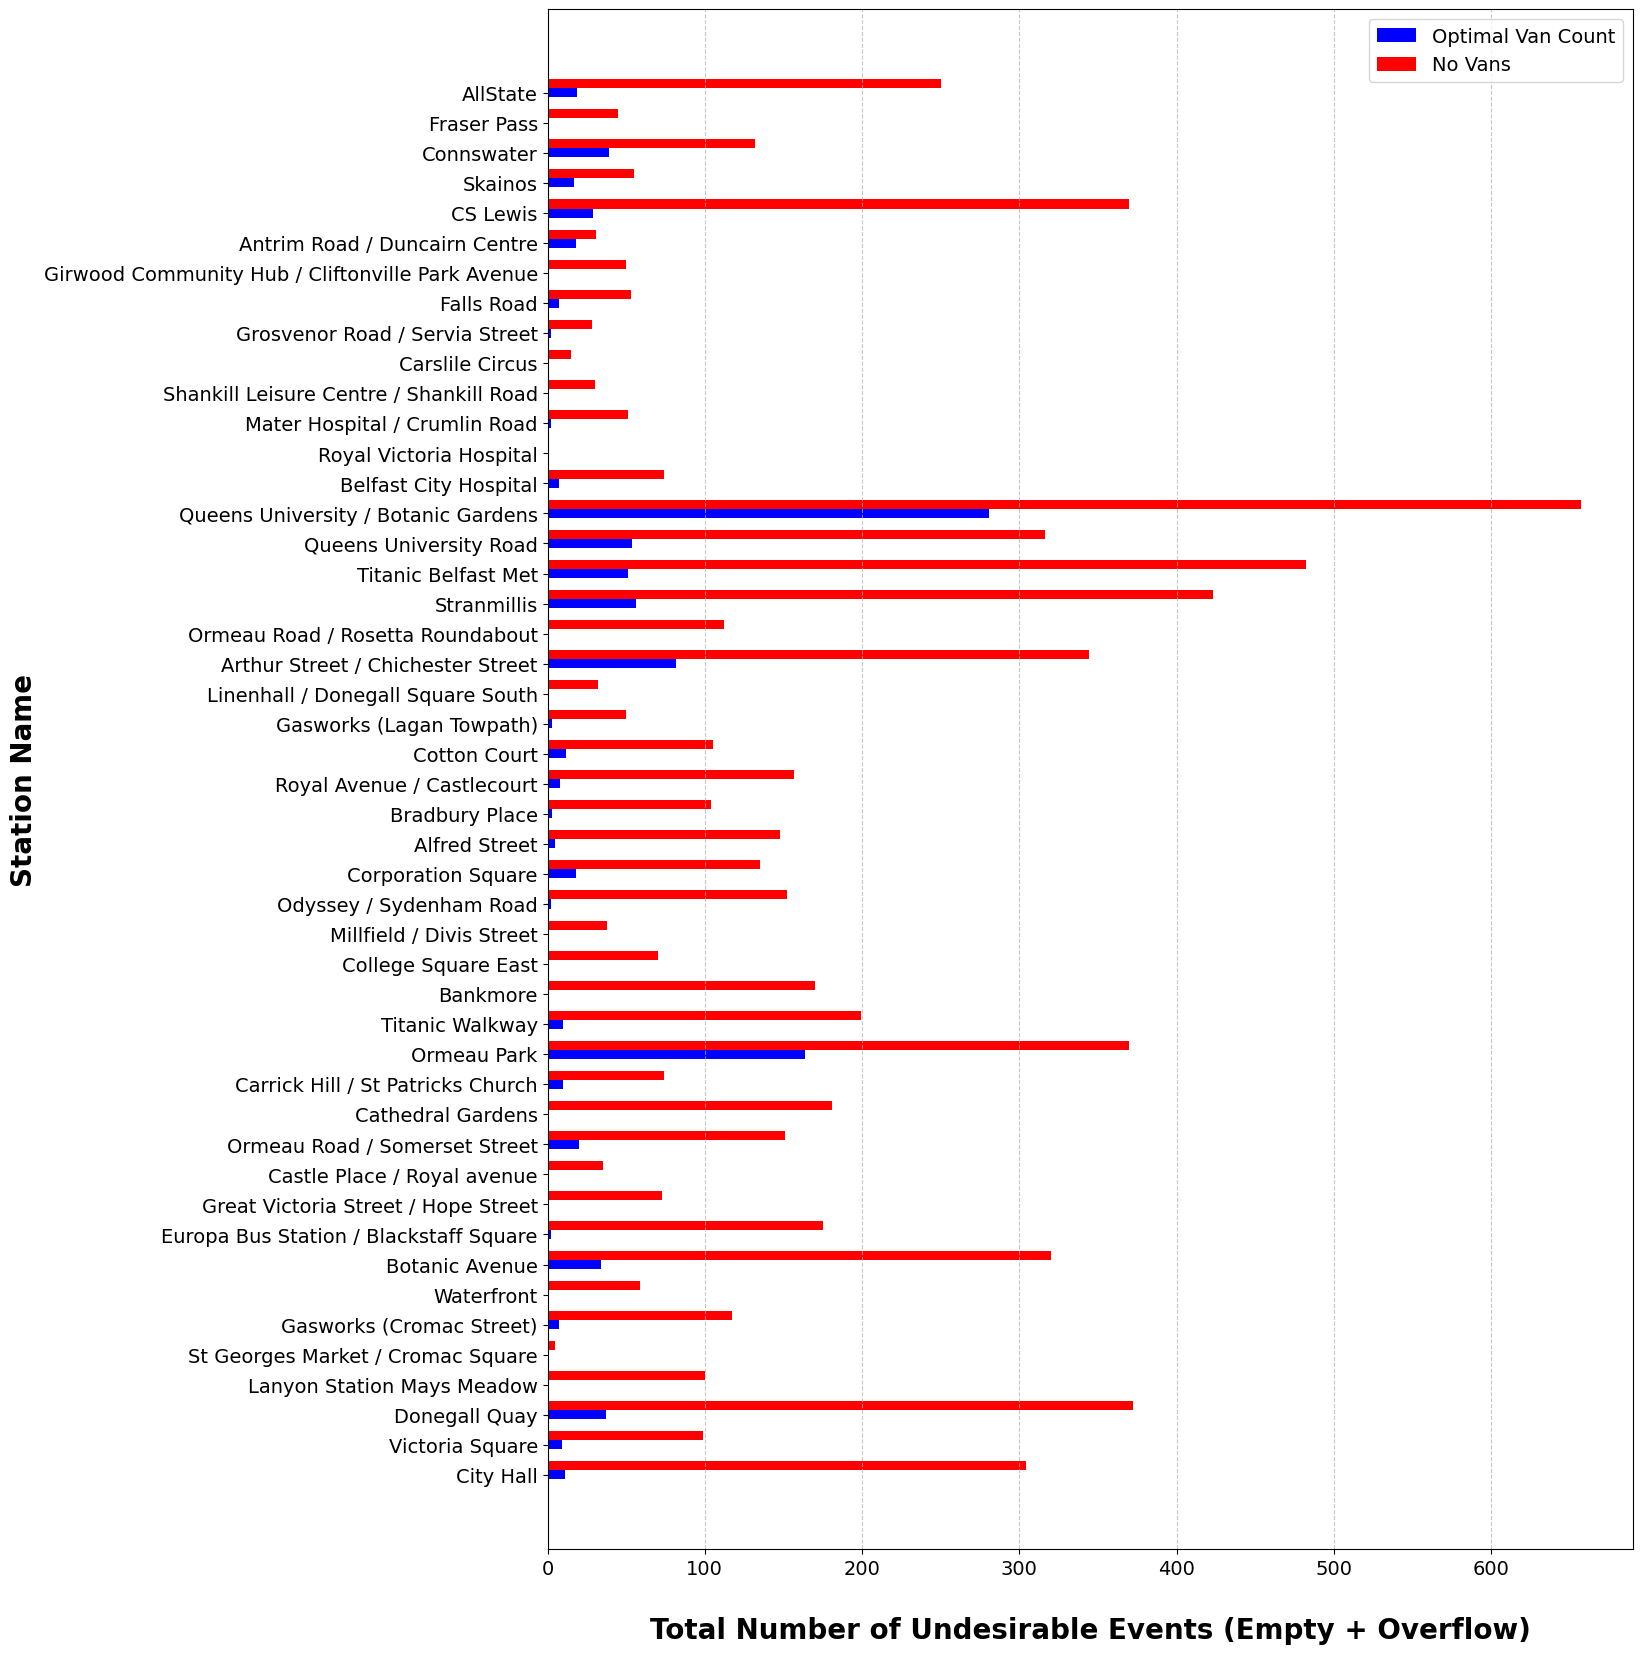

In [61]:
#Setting up the system
if __name__ == "__main__":

  #Mounting drive
  drive.mount('/content/drive')

  #Delcaring variables
  stationList = []
  maxNumBikes = 364
  numStations = 0
  numSteps = 30 * 24 * 60

  vanJourneysPerHour = 1
  workingHours = 8
  vanMaxCap = 20
  vanCount = 0
  maxNumberOfVans = 15
  optimalVanCount = 0

  results = []

  #Looping over the simulation for a varying number of van numbers
  for i in range(maxNumberOfVans + 1):

    #Declaring variables
    stationList = []

    #Setting seed
    seed = 3024
    random.seed(seed)
    np.random.seed(seed)

    #Getting station data
    stationList = getStationData(stationList)

    #Filling stations
    fillStations(stationList)

    #Getting number of stations
    numStations = len(stationList)

    #Getting van count and probability
    vanCount = i
    vanProb = (vanCount * vanJourneysPerHour * workingHours) / (24 * 60)

    #Running the simulation
    results.append(runSimulation(stationList, numSteps, numStations, vanProb, vanMaxCap))

  #Plotting graphs and getting optimal van count
  optimalVanCount = plotGraphsChangingNumVans(stationList, results)

  #Setting desiredVanCount
  desiredVanCount = 3

  #Printing results for base system
  printResults(stationList, results[0], numStations)

  #Plotting graphs for base system
  plotGraphs(stationList, results[0], 1)

  #Printing results for optimal van count
  printResults(stationList, results[desiredVanCount], numStations)

  #Plotting graphs for optimal van count
  plotGraphs(stationList, results[desiredVanCount], 2)

  #Plotting comparison of no vans and optimal van count
  plotComparison(stationList, results, desiredVanCount)

  #Extracting initial bike data from results
  initialBikeData = []
  for station in stationList:
    history = results[0][station.id]
    initialBikeCount = history[0]['bikeCount']
    initialBikeData.append({'Station Name': station.name, 'Number of Racks': station.maxCapacity, 'Initial Bikes': initialBikeCount})

  #Converting to DataFrame
  df = pd.DataFrame(initialBikeData)

  #Saving to Excel
  df.to_excel("initial_bike_distribution.xlsx", index=False)